# GRU generation huis




In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import time
# Gebruik de GPU als die er is, anders de CPU
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cuda


# Data inladen

In [3]:
df= pd.read_parquet('../../prepared_data/forecast_targets_with_weather.parquet')
huis_generation = df[(df['location'] == 'huis') & (df['target_type'] == 'generation')]
huis_generation = huis_generation.dropna(subset=['pow_imputed'])
huis_generation = huis_generation.dropna(subset=['Windrichting'])
huis_generation = huis_generation.dropna(subset=['WindSnelheid'])
huis_generation = huis_generation.dropna(subset=['LuchtVochtigheid'])


In [4]:
df.dtypes

timestamp           datetime64[ns, Europe/Amsterdam]
location                                      object
target_type                                   object
pow_w                                        float64
pow_imputed                                  float64
is_observed                                     bool
is_conflict                                     bool
is_imputed                                      bool
impute_methode                                object
Windrichting                                 float64
WindSnelheid                                 float64
Temperatuur                                  float64
GlobaleStraling                                int64
DuurNeerslag                                   int64
SomNeerslag                                  float64
LuchtVochtigheid                             float64
dtype: object

## voorspel instellingen

In [5]:
stap_per_dag = 24 * 12               # 288 per dag

aantal_dagen_input = 7               # aantal dagen voor input
input_len = aantal_dagen_input * stap_per_dag

aantal_dagen_forecast = 3            # =aantal dagen voorspelling
horizon = aantal_dagen_forecast * stap_per_dag

stride = 12                          # het venster schuift 12 stappen (1 uur) per voorbeeld op

TIME_COL = 'timestamp'   # pas aan naar de naam van jouw tijdkolom (of gebruik de index, zie onder)
tijd = pd.to_datetime(huis_generation[TIME_COL])
uur = tijd.dt.hour                                   # 0 t/m 23
dag_van_week = tijd.dt.dayofweek + uur / 24          # 0.0 t/m 6.96

huis_generation['uur_sin']  = np.sin(2 * np.pi * uur / 24)
huis_generation['uur_cos']  = np.cos(2 * np.pi * uur / 24)
huis_generation['week_sin'] = np.sin(2 * np.pi * dag_van_week / 7)
huis_generation['week_cos'] = np.cos(2 * np.pi * dag_van_week / 7)
rad = np.deg2rad(huis_generation['Windrichting'])
huis_generation['wind_sin'] = np.sin(rad)
huis_generation['wind_cos'] = np.cos(rad)

FEATURE_COLS = ['pow_imputed', 'uur_sin', 'uur_cos', 'week_sin', 'week_cos',
                'WindSnelheid', 'LuchtVochtigheid','Temperatuur','GlobaleStraling']
TARGET_COL = 'pow_imputed'                 # features (inclusief target)

TRAIN_FRAC = 0.70                    # deel van de data voor training
VAL_FRAC = 0.15                      # deel voor validatie data  ,de rest is test data

In [6]:
target = "pow_imputed"

corr = huis_generation[FEATURE_COLS].corr(numeric_only=True)

print(corr[target].sort_values(ascending=False))

pow_imputed         1.000000
LuchtVochtigheid    0.719673
uur_cos             0.596403
uur_sin             0.170151
week_sin            0.000460
week_cos           -0.014375
WindSnelheid       -0.237406
Temperatuur        -0.510978
GlobaleStraling    -0.867842
Name: pow_imputed, dtype: float64


In [7]:
n_features = len(FEATURE_COLS)
target_idx = FEATURE_COLS.index(TARGET_COL)

## chronologisch splisen

In [8]:
values = huis_generation[FEATURE_COLS].values

n = len(values)
i_train = int(n * TRAIN_FRAC)
i_val = int(n * (TRAIN_FRAC + VAL_FRAC))

train_raw = values[:i_train]
val_raw = values[i_train:i_val]
test_raw = values[i_val:]

## normaliseren

In [9]:
train_mean = train_raw.mean(axis=0)
train_std = train_raw.std(axis=0)

train = (train_raw - train_mean) / train_std
val = (val_raw - train_mean) / train_std
test = (test_raw - train_mean) / train_std

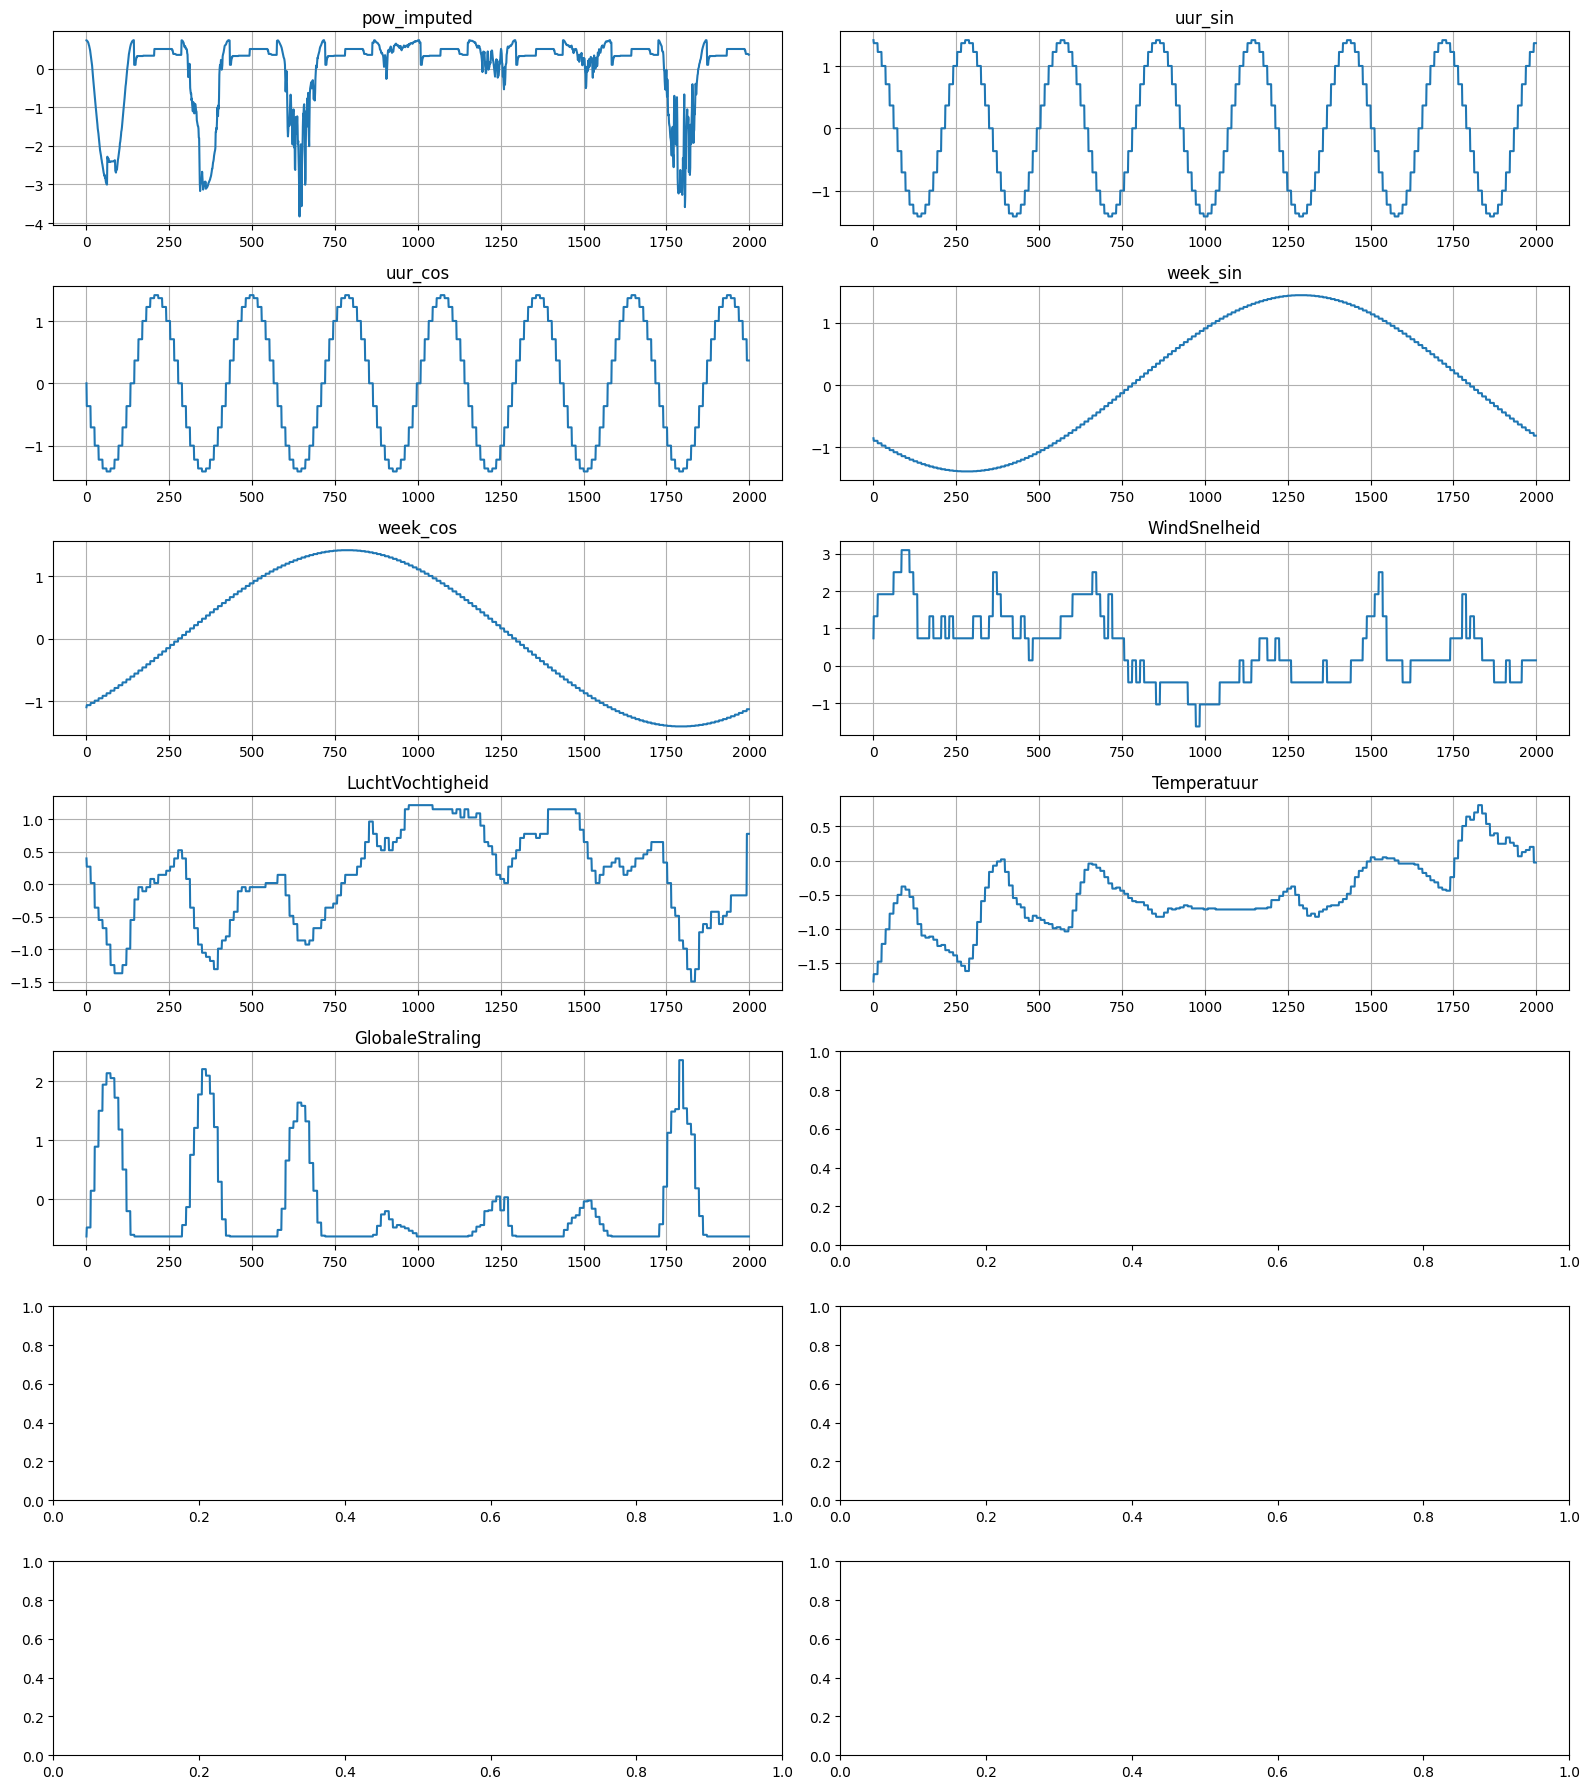

In [10]:
# features na normaliseren
fig, ax = plt.subplots(7, 2, figsize=(16, 18))
ax = ax.flatten()

for i, feature in enumerate(FEATURE_COLS):
    ax[i].plot(train[:2000, i])
    ax[i].set_title(feature)
    ax[i].grid(True)

plt.tight_layout()
plt.show()

In [14]:
class WindowDataset(Dataset):

    def __init__(self, data, input_len, horizon, target_idx, stride):
        self.data = torch.tensor(data, dtype=torch.float32)
        self.input_len = input_len
        self.horizon = horizon
        self.target_idx = target_idx

        # Hoeveel vensters passen er in de data? Elk venster heeft input_len + horizon stappen nodig
        n_vensters = len(data) - input_len - horizon + 1
        self.starts = range(0, max(n_vensters, 0), stride)

    # Bereken het aantal voorbeelden
    def __len__(self):
        return len(self.starts)

    # Haal voorbeeld nummer idx op
    def __getitem__(self, idx):
        s = self.starts[idx]
        x = self.data[s : s + self.input_len]                                   # geschiedenis
        y = self.data[s + self.input_len : s + self.input_len + self.horizon,   # toekomst,
                      self.target_idx]                                          # alleen de target
        return x, y

Creeer dataset voor de training, validatie en test data.

In [15]:
train_dataset = WindowDataset(train, input_len, horizon, target_idx, stride)
val_dataset = WindowDataset(val, input_len, horizon, target_idx, stride)
test_dataset = WindowDataset(test, input_len, horizon, target_idx, stride)

print("aantal voorbeelden | train:", len(train_dataset), "| val:", len(val_dataset), "| test:", len(test_dataset))

aantal voorbeelden | train: 13117 | val: 2623 | test: 2623


Creeer DataLoader 

In [16]:
batch_size = 32

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

## model

## training loop


In [17]:
hidden_sizes = [64,64]             # het aantal getallen van hidden size staat gelijk aan het aantal lagen 
dropout = 0.2                  
learning_rate = 1e-3
output_size = horizon           

class Customgru(nn.Module):
    def __init__(self, input_size, hidden_sizes, output_size, dropout=0.0):
        super().__init__()

        self.layers = nn.ModuleList()
        self.dropout = nn.Dropout(dropout)

        prev_size = input_size
        for h in hidden_sizes:
            self.layers.append(
                nn.GRU(input_size=prev_size,
                        hidden_size=h,
                        num_layers=1,
                        batch_first=True)
            )
            prev_size = h

        self.fc = nn.Linear(hidden_sizes[-1], output_size)

    def forward(self, x):
        out = x
        for lstm in self.layers:
            out, _ = lstm(out)
            out = self.dropout(out)

        out = out[:, -1, :]
        return self.fc(out)


model = Customgru(
    input_size=n_features,
    hidden_sizes=hidden_sizes,
    output_size=horizon,
    dropout=0.2
).to(DEVICE)

criterion = nn.L1Loss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

print("CUSTOM gru |", sum(p.numel() for p in model.parameters()), "parameters")


CUSTOM gru | 96480 parameters


In [36]:
n_epochs = 20
train_loss_list = []
val_loss_list = []
epoch_time_list = []

std_target = train_std[target_idx]                    # NIEUW: standaarddeviatie van de target

if DEVICE == "cuda":
    torch.cuda.synchronize()
start_totaal = time.perf_counter()                    # start tijd

for epoch in range(n_epochs):
    start_epoch = time.perf_counter()
    # Trainen
    model.train()
    running_loss = 0.0

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)

        optimizer.zero_grad()
        output = model(inputs)
        loss = criterion(output, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * targets.shape[0]

    train_loss = running_loss / len(train_dataset)
    train_loss_list.append(train_loss)

    # Validatie
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            loss = criterion(model(inputs), targets)
            val_loss += loss.item() * targets.shape[0]
    val_loss = val_loss / len(val_dataset)
    val_loss_list.append(val_loss)

    if DEVICE == "cuda":
        torch.cuda.synchronize()
    epoch_tijd = time.perf_counter() - start_epoch    # epoch train tijd berekenen
    epoch_time_list.append(epoch_tijd)

    print(f"Epoch {epoch+1}/{n_epochs}, "
          f"train loss: {train_loss:.4f} (echte MAE: {train_loss * std_target:.1f}), "   
          f"validation loss: {val_loss:.4f} (echte MAE: {val_loss * std_target:.1f}), " )

totale_tijd = time.perf_counter() - start_totaal      # totale tijd berekenen
print(f"\nTotale trainingstijd: {totale_tijd:.1f}s ({totale_tijd/60:.1f} min)")
print(f"Gemiddeld per epoch: {np.mean(epoch_time_list):.1f}s")

Epoch 1/20, train loss: 0.2563 (echte MAE: 154.5), validation loss: 0.4193 (echte MAE: 252.7), 
Epoch 2/20, train loss: 0.2551 (echte MAE: 153.7), validation loss: 0.4276 (echte MAE: 257.7), 
Epoch 3/20, train loss: 0.2541 (echte MAE: 153.2), validation loss: 0.4271 (echte MAE: 257.4), 
Epoch 4/20, train loss: 0.2530 (echte MAE: 152.5), validation loss: 0.4122 (echte MAE: 248.5), 
Epoch 5/20, train loss: 0.2528 (echte MAE: 152.3), validation loss: 0.4216 (echte MAE: 254.1), 
Epoch 6/20, train loss: 0.2511 (echte MAE: 151.4), validation loss: 0.4185 (echte MAE: 252.2), 
Epoch 7/20, train loss: 0.2505 (echte MAE: 151.0), validation loss: 0.4154 (echte MAE: 250.4), 
Epoch 8/20, train loss: 0.2498 (echte MAE: 150.6), validation loss: 0.4174 (echte MAE: 251.6), 
Epoch 9/20, train loss: 0.2494 (echte MAE: 150.3), validation loss: 0.4174 (echte MAE: 251.6), 
Epoch 10/20, train loss: 0.2489 (echte MAE: 150.0), validation loss: 0.4362 (echte MAE: 262.9), 
Epoch 11/20, train loss: 0.2481 (echte 

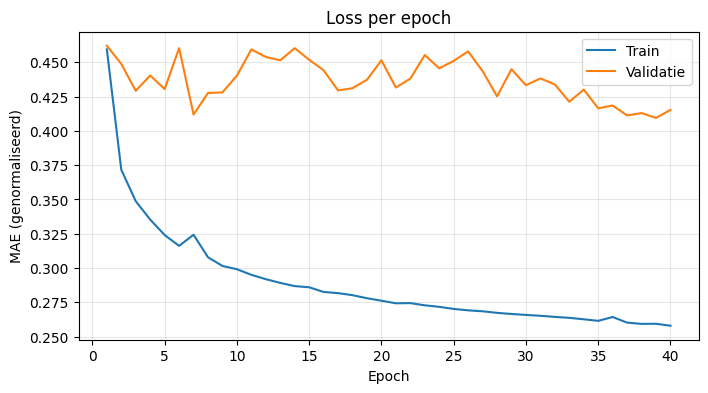

In [19]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, n_epochs + 1), train_loss_list, label='Train')
plt.plot(range(1, n_epochs + 1), val_loss_list, label='Validatie')
plt.xlabel('Epoch')
plt.ylabel('MAE (genormaliseerd)')
plt.title('Loss per epoch')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

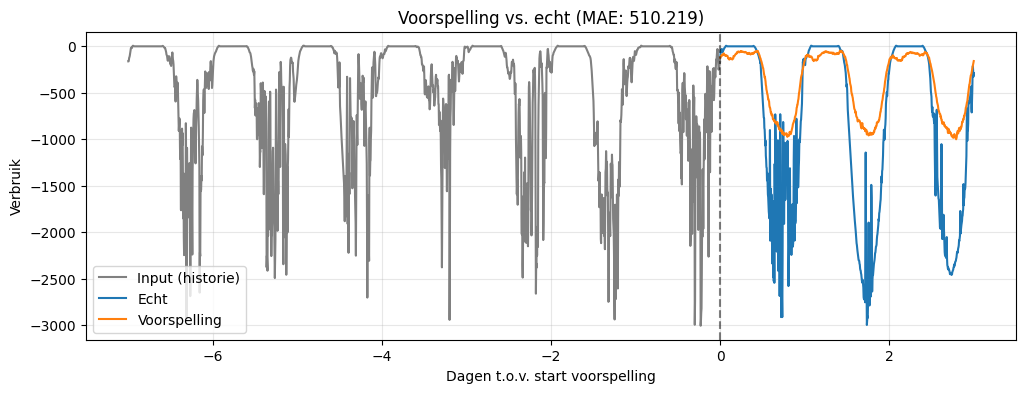

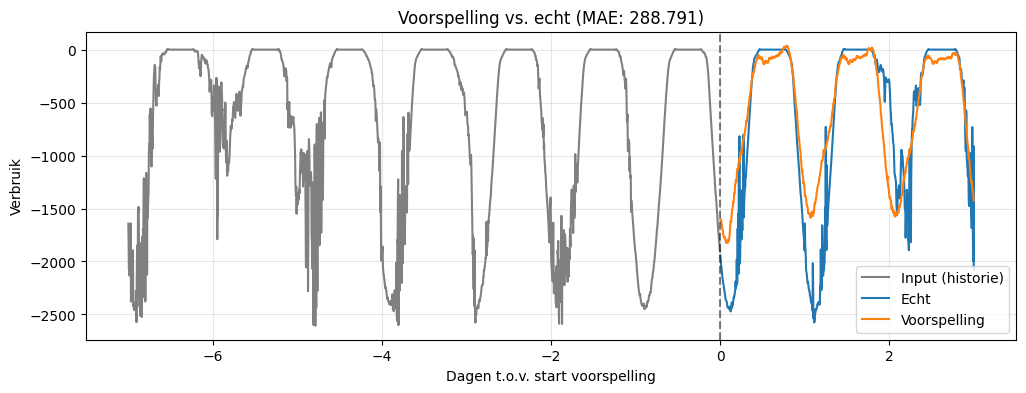

In [20]:
def plot_voorspelling(dataset, idx=0, titel='Voorspelling vs. echt'):
    model.eval()
    x, y = dataset[idx]
    with torch.no_grad():
        pred = model(x.unsqueeze(0).to(DEVICE)).cpu().numpy().flatten()

    # terug naar originele eenheid (de-normaliseren)
    m, s = train_mean[target_idx], train_std[target_idx]
    hist = x[:, target_idx].numpy() * s + m
    echt = y.numpy() * s + m
    pred = pred * s + m

    mae = np.abs(pred - echt).mean()

    t_hist = np.arange(-input_len, 0) / stap_per_dag     # x-as in dagen
    t_fc = np.arange(horizon) / stap_per_dag

    plt.figure(figsize=(12, 4))
    plt.plot(t_hist, hist, color='grey', label='Input (historie)')
    plt.plot(t_fc, echt, label='Echt')
    plt.plot(t_fc, pred, label='Voorspelling')
    plt.axvline(0, color='black', linestyle='--', alpha=0.5)
    plt.xlabel('Dagen t.o.v. start voorspelling')
    plt.ylabel('Verbruik')
    plt.title(f'{titel} (MAE: {mae:.3f})')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

plot_voorspelling(test_dataset, idx=0)
plot_voorspelling(test_dataset, idx=len(test_dataset) // 2)   # een ander moment

MAE totaal: 310 W
Dag 1: 305 W
Dag 2: 314 W
Dag 3: 312 W


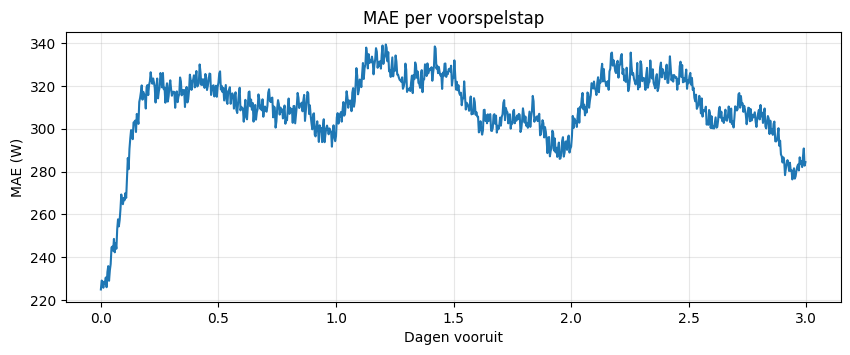

In [21]:
model.eval()
fouten = []
with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
        fouten.append((model(inputs) - targets).abs().cpu())
fouten = torch.cat(fouten).numpy() * std_target     

mae_per_stap = fouten.mean(axis=0)
print(f"MAE totaal: {fouten.mean():.0f} W")
for d in range(aantal_dagen_forecast):
    s = slice(d * stap_per_dag, (d + 1) * stap_per_dag)
    print(f"Dag {d+1}: {mae_per_stap[s].mean():.0f} W")

plt.figure(figsize=(10, 3.5))
plt.plot(np.arange(horizon) / stap_per_dag, mae_per_stap)
plt.xlabel('Dagen vooruit')
plt.ylabel('MAE (W)')
plt.title('MAE per voorspelstap')
plt.grid(alpha=0.3)
plt.show()